In this notebook a *Naive* clustering of the dataset with **2 or less hits per even**t is done. Three **standard clustering** algorithm are used without a deep parameter search. 

# 0 - General Set-Up

In this section general set up is done: import, dataset loading and processing.

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.pipeline import make_pipeline

import sys
from pathlib import Path

sys.path.append(str(Path("../../../src/utils").resolve()))
from dataset_balancing import balance_dataset

To ensure corretct reproduction: 

In [2]:
random_state = 42
np.random.seed(random_state)

In [3]:
file_path = "../../../data/Background/Engineered_Datasets/"
file_name = "less2_hit_dataset.csv"

ds = pd.read_csv(file_path + file_name, header=0)
print(f"Dataset shape perfore balancing: {ds.shape}")

n_samples = 1000
ds = balance_dataset(ds, target_col="particle_type", n_samples = n_samples, random_state=random_state)
print(f"Dataset shape after balancing: {ds.shape}")

Dataset shape perfore balancing: (284028, 7)
Dataset shape after balancing: (11000, 7)


## Data Pre-Processing

Dropping of meaningless feature is perfomed. Then convert data values to help clustering algorithm to properly work:
- Convert in log scale the Energy-based features in order to prevent unbalanced distance computation by clustering algorithm:
$log_{10}(x+1)$
- Apply `StandardScaler(with_std=False)` to maps the values to normal-like distribution (to prevent extreme values from distorting distance calcualtion) 
- Apply `PowerTransformer(standardize=True)` to rescale to unit variance.



In [4]:
X = ds.drop(columns=["particle_type", "pixel_ijk"])
X.shape

(11000, 5)

In [5]:
log_cols = [c for c in X.columns if "E_" in c]
print(f"Columns to be log-transformed: {log_cols}")

for col in log_cols:
    X[col] = np.log10(X[col] + 1)

Columns to be log-transformed: ['E_sum']


In [6]:
preprocessor = make_pipeline(
    StandardScaler(with_std=False),
    PowerTransformer(standardize=True),
)

X_transformed = pd.DataFrame(preprocessor.fit_transform(X), columns=X.columns)

Plot the difference of `E_sum` feature values after each pre-processing step:

Text(0.5, 1.0, 'Final E_sum \n(Standardized + Power Transformed)')

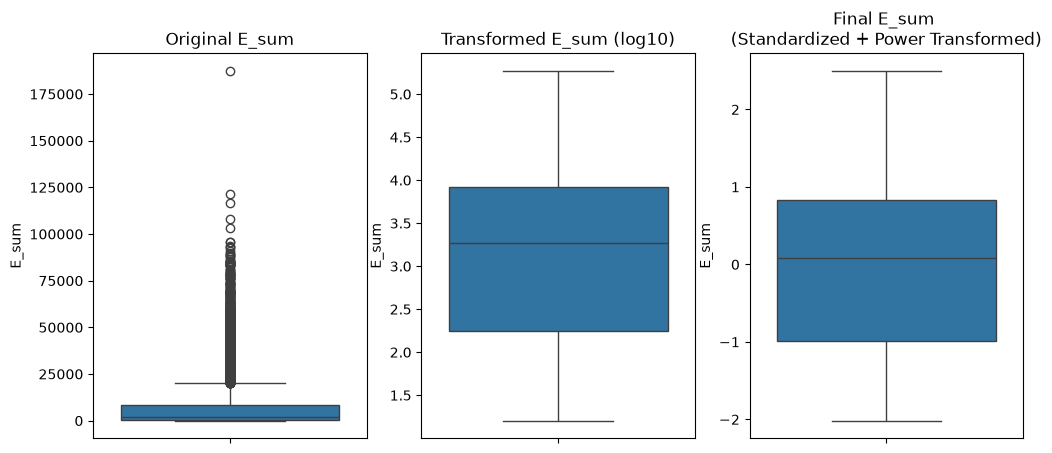

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
axes = axes.flatten()

feat = "E_sum"
sns.boxplot(data=ds[feat], ax=axes[0])
axes[0].set_title("Original E_sum")

sns.boxplot(data=X[feat], ax=axes[1])
axes[1].set_title("Transformed E_sum (log10)")

sns.boxplot(data=X_transformed[feat], ax=axes[2])
axes[2].set_title("Final E_sum \n(Standardized + Power Transformed)")

Recap of data in the dataset:

In [8]:
print(f"Shape of X_transformed: {X_transformed.shape}")
X_transformed.describe(include="all")

Shape of X_transformed: (11000, 5)


,E_sum,com_x,com_y,com_z,hits_sum
count,11000.000000,1.100000e+04,1.100000e+04,1.100000e+04,11000.000000
mean,0.000000,-4.069472e-17,7.751375e-18,5.684342e-17,0.000000
std,1.000045,1.000045e+00,1.000045e+00,1.000045e+00,1.000045
min,-2.016378,-1.334444e+00,-1.383709e+00,-1.317216e+00,-0.603537
25%,-0.987238,-1.030578e+00,-1.096998e+00,-9.861421e-01,-0.603537
50%,0.088427,-8.016723e-02,8.320199e-02,-2.805171e-02,-0.603537
75%,0.836063,1.046054e+00,1.030087e+00,1.055926e+00,1.656900
max,2.500770,1.335678e+00,1.352385e+00,1.385682e+00,1.656900


# 1 - Clustering

In this section 3 main clustering approach are tried:
- **KMeans**: Divide the dataset into $k$ *predefined* clusters byß assigning each observation to the nearest centroid and recalculating centroids to minimize within-cluster sum of squares. Fast and scalable, but uses spherical and same sized clusters. $k$ is specified as hyperparameter.
- **Agglomerative Clustering**: Starts by treating each sample as a single cluster and recursively merges the closest pairs of clusters based on a linkage criterion. Builds a full hierarchy (called *dendrogram*) and cut at a target cluster count $k$. High memory and computational overhead.
- **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise): Identifies clusters as continuous high-density areas separated by low-density zones using a neighborhood radius (`eps`) and a minimum number of points (`min_samples`). It discovers arbitrarily shaped and non-linear clusters. It does not neet the number of clusters in advance, and automatically flags noise (outliers).

## 1.1 - KMeans

The evaluation of the results is done using the following metrics:

- **Inertia:** Measures the cohesion of points inside the same cluster (does not account for separation between clusters). Smaller value correspond to more compact clusters, but a 0 value means that each point is a cluster ($K = N$), so it's needed the ***Elbown Method***: value of $K$ after which adding a new cluster wuold not improve significantly the inertia score. The formula of inertia is:

  $$\text{Inertia} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \Vert x_i - \mu_k \Vert^2$$

- **Silhouette Score:** Measures both intra-cluster cohesion and inter-cluster separation. It's value is $\in[-1,+1]$, if the value is $\ge0.5$ the clusterization is "solid". The formula is:

  $$s(i) = \frac{b(i) - a(i)}{\max(a(i),\, b(i))}$$

    - where a(i) is the mean distance between i and all other point in the same cluster; 
  - and b(i) is the mean distance between i and all points in the closest cluster 



Try clustering with [2, 11) clusters:

In [9]:
k_range = range(2, 11)
params = {
    "n_clusters": [*k_range],
    # "init": ["k-means++", "random"],
    #n_init": [10, 20, 30],
    #"max_iter": [300, 500, 1000],
}
pg = list(ParameterGrid(params))

In [10]:
km_df = pd.DataFrame(columns=["n_clusters", "inertia",  "silhouette"])

for k in range(len(pg)):
    km = KMeans(**(pg[k]), random_state=random_state)
    ypred = km.fit_predict(X_transformed)

    km_df.loc[len(km_df)]=[
        
        pg[k]["n_clusters"],
        km.inertia_,
        silhouette_score(X_transformed, ypred)
    ]

# km_df = km_df.sort_values(by="silhouette", ascending=False).reset_index(drop=True)
km_df.sort_values(by="silhouette", ascending=False).head(n=10)

,n_clusters,inertia,silhouette
0,2.0,42564.858775,0.263420
8,10.0,19775.687749,0.232974
7,9.0,21106.691343,0.229158
4,6.0,26562.842797,0.217814
5,7.0,24566.517152,0.216454
6,8.0,22858.153158,0.216300
1,3.0,35959.365851,0.214123
3,5.0,28915.645957,0.208500
2,4.0,32186.385603,0.196314


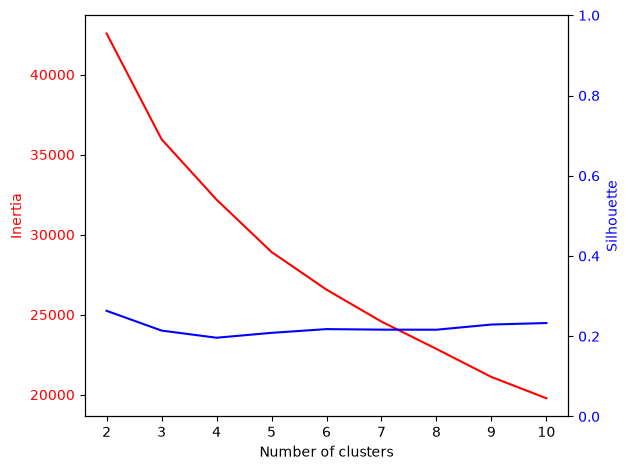

In [11]:
fig, ax1 = plt.subplots()

color = "red"
ax1.set_xlabel("Number of clusters")
ax1.set_ylabel("Inertia", color=color)
ax1.plot(k_range, km_df["inertia"], color=color)
ax1.tick_params(axis="y", labelcolor=color)
ax2 = ax1.twinx()

color = "blue"
ax2.set_xlabel("Number of clusters")
ax2.set_ylabel("Silhouette", color=color)
ax2.plot(k_range, km_df["silhouette"], color=color)
ax2.tick_params(axis="y", labelcolor=color)
ax2.set_ylim(0,1)

fig.tight_layout()
plt.show()

Using the elbow method, we can use 4/5 clusters. <u>⚠️Note</u>: the silhouette score is too small meaning closer clusters. 

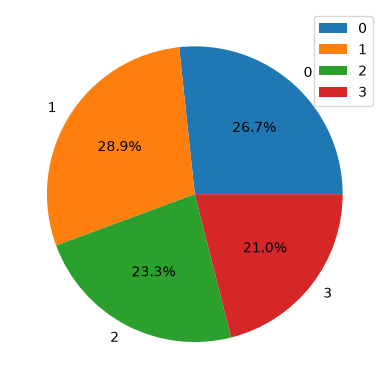

In [12]:
km = KMeans(n_clusters=4, random_state=random_state)
y_km = km.fit_predict(X_transformed)

clust_size_km = np.unique(y_km,return_counts=True)
pd.DataFrame(clust_size_km[1]).plot.pie(y=0, autopct="%1.1f%%")
plt.show()

## 1.2 - Agglomerative Clustering

Single data are indinvidual cluster at the beginning of the algorithm, then based on *Linkage Criterion* data points are grouped togheter: dissimilar data points are kept in separate clusters, and similar ones are grouped in one cluster. There are 4 main linkage criterion:
- **Single**: merges cluster with shortest distance between any pairs of points. Can create clusters with irregular shapes.
- **Complete**: merges two cluster with maximum distance between points is minimum. Compact spherical clusters. In encourage well-separated clusters. If two clusters are merged based on the closest points (as with Single Linkage), it can mistakenly link distant points just because of a small local similarity, Complete Linkage prevents this by considering all points, reducing noise sensitivity.
- **Average**: computes avereage distance between all pairs of points. Create balanced clusters.
- **Ward**: merges clusters with smallest increse in variance. 

In [13]:
parameters = [
    {
        "n_clusters": k_range,
        "linkage" : ["ward", "complete", "average", "single"]
    }
]
pg = list(ParameterGrid(parameters))

In [14]:
result_ac = []
for i in range(len(pg)):
    ac = AgglomerativeClustering(**(pg[i]))
    y_ac = ac.fit_predict(X_transformed)
    result_ac.append(
        [
            pg[i]["linkage"],
            pg[i]["n_clusters"],
            silhouette_score(X_transformed,y_ac)
        ]
    )

df_result_ac = pd.DataFrame(data = result_ac, columns=["linkage","n_clusters","silhouette_score"])
df_result_ac.sort_values(by="silhouette_score", ascending=False)

,linkage,n_clusters,silhouette_score
0,ward,2,0.263420
27,single,2,0.263420
18,average,2,0.263420
28,single,3,0.200651
1,ward,3,0.188061
26,average,10,0.181689
2,ward,4,0.170641
25,average,9,0.170501
24,average,8,0.166546
20,average,4,0.165538


As we can see from the results table, the top 3 row have the highest, very similar, silhouette score (still a small value). Incresing the number of clusters decrese drastically the score. 

In [15]:
## Chose the best model based on silhouette score: take index of the table
index_best_model = df_result_ac["silhouette_score"].idxmax()
print(f"Best model index: {index_best_model} which corresponds to \n{df_result_ac.iloc[index_best_model]}")

ac = AgglomerativeClustering(**(pg[index_best_model]))
y_ac = ac.fit_predict(X_transformed)

Best model index: 0 which corresponds to 
linkage                ward
n_clusters                2
silhouette_score    0.26342
Name: 0, dtype: object


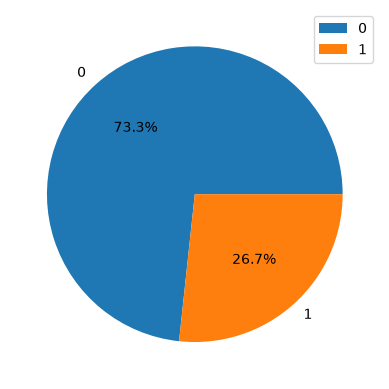

In [16]:
clust_sizes_ac = np.unique(y_ac,return_counts=True)
pd.DataFrame(clust_sizes_ac[1]).plot.pie(y=0, autopct='%1.1f%%', );
plt.show()

## 1.3 - DBSCAN

Two main parameters:
- **Epsilon** (`eps`): maximum distance allowed between two point within the same cluster. 
- **Minimum Samples** (`min_samples`): mimum number of points required to forma distinct cluster. 

In [17]:
param_grid = {
    "eps":          list(np.arange(0.001, 1, 0.005)),
    "min_samples":  list(range(2,10,1))
}
params = list(ParameterGrid(param_grid))

In [18]:
dbscan_out = pd.DataFrame(columns =  ['eps','min_samples','n_clusters','silhouette', 'unclust%'])

for i in range(len(params)):
    db = DBSCAN(**(params[i]))
    y_db = db.fit_predict(X_transformed)

    # count the number of clusters and the number of noise points
    cluster_labels_all = np.unique(y_db)
    cluster_labels = cluster_labels_all[cluster_labels_all != -1]
    n_clusters = len(cluster_labels)

    # Only compute silhouette score if there are at least 2 clusters and less than the number of samples
    if 1 < n_clusters and n_clusters < len(y_db):

        # Filter out noise points for silhouette score calculation
        X_cl = X_transformed.loc[y_db!=-1,:]
        y_db_cl = y_db[y_db!=-1]
        silhouette = silhouette_score(X_cl,y_db_cl)

        # Calculate the percentage of unclustered points
        uncl_p = (1 - y_db_cl.shape[0]/y_db.shape[0]) * 100
        dbscan_out.loc[len(dbscan_out)] = [
            db.eps, 
            db.min_samples,
            n_clusters, 
            silhouette,
            uncl_p
        ]

In [19]:
sil_thr = 0.2   # visualize results only for combinations with silhouette above the threshold
unc_thr = 5     # visualize results only for combinations with unclustered% below the threshold
n_clu_max_thr = 5

dbscan_out[(dbscan_out['silhouette']>=sil_thr)\
         & (dbscan_out['unclust%']<=unc_thr)\
         & (dbscan_out['n_clusters']<=n_clu_max_thr)].sort_values(['silhouette','unclust%'],ascending=[False,True])

,eps,min_samples,n_clusters,silhouette,unclust%
821,0.526,9.0,2.0,0.265611,2.400000
801,0.516,5.0,2.0,0.263845,0.727273
893,0.571,9.0,2.0,0.263795,0.863636
809,0.521,5.0,2.0,0.263764,0.663636
901,0.576,9.0,2.0,0.263728,0.800000
...,...,...,...,...,...
1093,0.696,9.0,2.0,0.263406,0.063636
1101,0.701,9.0,2.0,0.263406,0.063636
1109,0.706,9.0,2.0,0.263406,0.063636
928,0.596,4.0,2.0,0.263403,0.127273


In [20]:
# dbscan_out[(dbscan_out['n_clusters']==2)].sort_values(['silhouette','unclust%'],ascending=[False,True])

In [21]:
best = {'eps': 0.526, 'min_samples': 9}
# db = DBSCAN(**(params[db_best_par]))
db = DBSCAN(**best)
y_db = db.fit_predict(X_transformed)

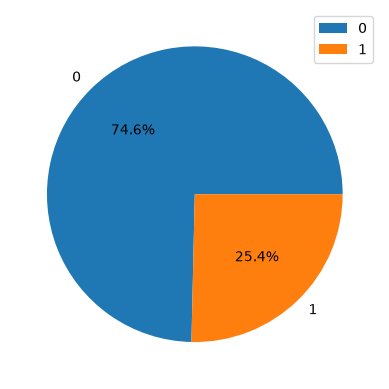

In [22]:
clust_sizes_db = np.unique(y_db[y_db!=-1],return_counts=True)
pd.DataFrame(clust_sizes_db[1]).plot.pie(y=0, autopct='%1.1f%%');
plt.show()

# 2 - Results

In this section a comparison of results is done.

In [32]:
X_transformed['cluster_km'] = y_km
X_transformed['cluster_ac'] = y_ac
X_transformed['cluster_db'] = y_db

algs = {
    "km": "KMeans", 
    "ac": "Agglomerative", 
    "db": "DBSCAN"
}
feat = X.columns.to_list()  # all features


In [33]:

# ncols = 3
# nrows = int(np.ceil(len(feat) / ncols))

# for a, name in algs.items():
#     cl_col = f"cluster_{a}"
#     print(f"Cluster sizes for {name}:")
#     print(X_transformed[cl_col].value_counts().sort_index(), "\n")

#     fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3.5 * nrows))
#     axes = axes.flatten()

#     for ax, col in zip(axes, feat):
#         sns.boxplot(
#             data=X_transformed, 
#             x=col, 
#             y=X_transformed[cl_col].astype(str),
#             order=sorted(X_transformed[cl_col].astype(str).unique()), 
#             ax=ax
#         )
#         ax.set_title(col)
#         ax.set_xlabel("")
#         ax.set_ylabel("cluster")

#     for ax in axes[len(feat):]:  
#         ax.axis("off")

#     fig.suptitle(f"{name}: feature distributions by cluster", y=1.02)
#     plt.tight_layout()
#     plt.show()


Plot a heatmap of clusters division: to have a perfect clustering each cluster should have a class with a value close to 1 and all orther close to 0.

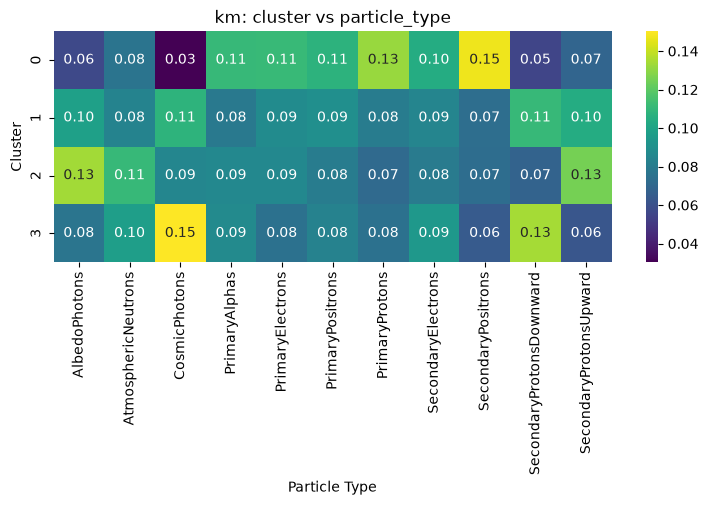

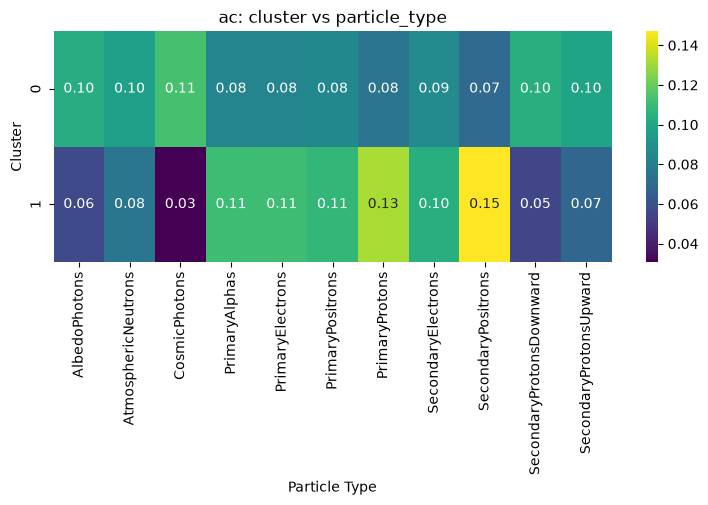

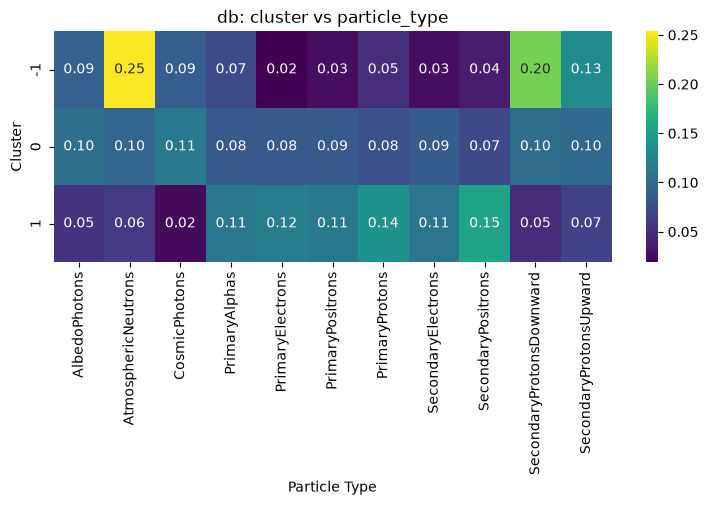

In [34]:
feat = X.columns.to_list()  # all features
y_true = ds["particle_type"].values

# 1) Cluster vs Real class: 
for a in algs.keys():
    ct = pd.crosstab(
        X_transformed[f"cluster_{a}"], 
        y_true, 
        normalize="index"
    )
    plt.figure(figsize=(9, 3))
    sns.heatmap(ct, annot=True, fmt=".2f", cmap="viridis")
    plt.title(f"{a}: cluster vs particle_type")
    plt.xlabel("Particle Type")
    plt.ylabel("Cluster")
    plt.show()


<u>NOTE</u>:Heatmap is row-normalized, so in DBSCAN there is not a large number of unclustered!

Plot heatmaps to visualize the mean of a feature inside each cluster:

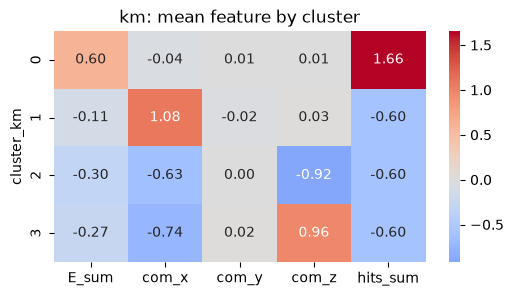

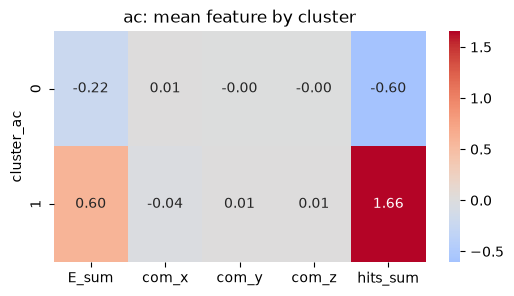

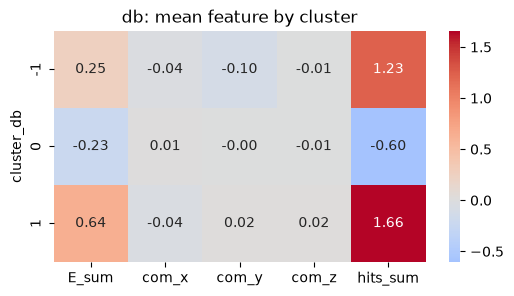

In [35]:

# 2) Mean profile by cluster
for a in algs.keys():
    prof = X_transformed.groupby(f"cluster_{a}")[feat].mean()
    plt.figure(figsize=(6, 3)); 
    sns.heatmap(
        prof, 
        annot=True, 
        fmt=".2f", 
        cmap="coolwarm", 
        center=0
    )
    plt.title(f"{a}: mean feature by cluster"); 
    plt.show()

- **KMeans**: no cluster have predominat particle (or families of particle), it is "balanced". We can see that clusters are mainly based on the hits_sum and the COM on Z axis.
- **Agglomerative Clustering**: clusters are balanced wrt the particle type. Cluster are mainly build on the hits_sum (1 or 2) [Binary filter].
- **DBSCAN**: There is no cluster with predominant particle type (or families of particle). Clusters are mainly build upon hits_sum and E_sum.

# 3 - Conclusions

As the results shows, the clustering is mainly based on the number of hits and the position of the COM (which in case of 1 hit is of course the hit position). A improvement may happen if a further dataset division is done: single hit and 2 hit event. 
<br><br>
For **single hit** event the only feature which can be used to discriminate **may be** E_sum.
<br><br>
A set of new feature can be used for the **2 hit event** as the span (the distance between hits) and the energy realese in each position.

Sources: 

- https://medium.com/@avantika10roy/agglomerative-clustering-explained-from-single-points-to-meaningful-groups-c2a6e3d4bdf6

- https://medium.com/@tarammullin/dbscan-2788cfce9389